# From Call Reports to Annualized Credit Losses

**Evidence: Recorded source-audit excerpt; Synthetic demonstration.** This guide
reads committed field definitions and an audit excerpt, then uses a separate,
fictional bank to explain rate construction. It does not open the original FFIEC
archives, download filings, or reconstruct the historical panel.

**Research question:** why can the same quarterly credit loss be misstated by a
YTD convention, a reporting-scope change, a denominator choice, or a missing value?
The economic object is an accounting loss flow relative to the loans supporting
that flow. A superficially plausible ratio can compare incompatible objects.

[Project](../README.md) · [Data definitions](../docs/data.md) ·
[Next: forecast evidence](02_benchmarks_and_forecast_evidence.ipynb)

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from bankstress.research_guides import repository_root

ROOT = repository_root()
pd.set_option("display.max_columns", 8)
pd.set_option("display.width", 100)
plt.rcParams.update({"figure.figsize": (8, 3.4), "font.size": 10})

## Follow a recorded field, not an invented history

The selected key is bank **12311**, **2007-12-31**, **CRE**. The audit stores raw
field values, archive/member labels, and the earlier review conclusion. We require
exactly one matching row. The field map supplies units, stock/flow classification,
and applicable forms; a mapping that allows 031/041 does **not** establish which
form this bank actually filed. Monetary values below are USD thousands.

In [2]:
audit = pd.read_csv(ROOT / "metadata/manual_source_audit.csv", dtype={"bank_id": str})
selected = audit.loc[audit.bank_id.eq("12311") & audit.report_date.eq("2007-12-31") & audit.segment.eq("CRE")]
assert len(selected) == 1, "Expected one audit record: 12311/2007-12-31/CRE"
record = selected.iloc[0]
mapping = pd.read_csv(ROOT / "metadata/field_mapping.csv", dtype={"form": str})
codes = ["RIAD3582", "RIAD3588", "RIAD3590", "RIAD3583", "RIAD3589", "RIAD3591"]
display(mapping.loc[mapping.raw_code.isin(codes),
                    ["raw_code", "standard_metric", "form", "stock_flow", "unit"]])
lineage = record.source_archive_members.split("; ")
display(pd.DataFrame([item.split("::") for item in dict.fromkeys(lineage)], columns=["Archive label", "Member label"]))
print("Recorded review conclusion:", record.reviewer_conclusion)

,raw_code,standard_metric,form,stock_flow,unit
25,RIAD3582,charge_off,031/041,flow,thousands
26,RIAD3583,recovery,031/041,flow,thousands
31,RIAD3588,charge_off,031/041,flow,thousands
32,RIAD3589,recovery,031/041,flow,thousands
33,RIAD3590,charge_off,031/041,flow,thousands
34,RIAD3591,recovery,031/041,flow,thousands


,Archive label,Member label
0,FFIEC CDR Call Bulk All Schedules 09302007.zip,FFIEC CDR Call Schedule RIBI 09302007.txt
1,FFIEC CDR Call Bulk All Schedules 12312007.zip,FFIEC CDR Call Schedule RIBI 12312007.txt


Recorded review conclusion: PASS


## Recover the limited arithmetic the excerpt supports

For a non-Q1 flow, the quarter's amount is current YTD minus the preceding
quarter's YTD. The adapter parses the recorded tokens and checks archive-quarter
alignment; `quarterize_ytd` performs the existing transformation. The prior rows
are supplied only to difference Q4: without Q2 they cannot themselves reconstruct
Q3 flows. Summing complete charge-off and recovery components yields net
charge-offs (NCO), which we compare with the saved audit totals.

In [3]:
from bankstress.research_guides import audit_flow_inputs
from bankstress.transform.flows import quarterize_ytd

inputs = audit_flow_inputs(ROOT, "12311", "2007-12-31", "CRE")
quarterized = quarterize_ytd(inputs)
q4 = quarterized.loc[quarterized.report_date.eq(pd.Timestamp("2007-12-31"))]
assert q4.quarterly_value.notna().all()
totals = q4.groupby("standard_metric").quarterly_value.sum()
nco = totals["charge_off"] - totals["recovery"]
np.testing.assert_allclose([totals["charge_off"], totals["recovery"], nco, nco],
    record[["quarterly_charge_off_thousands", "quarterly_recovery_thousands",
            "derived_segment_nco_thousands", "panel_segment_nco_thousands"]].astype(float))
display(q4[["raw_code", "standard_metric", "numeric_value", "quarterly_value"]].rename(
    columns={"numeric_value": "Current YTD (USD thousands)", "quarterly_value": "Quarterly (USD thousands)"}))
print(f"Recorded source-audit excerpt: quarterly NCO = {nco:,.0f} USD thousands")

,raw_code,standard_metric,Current YTD (USD thousands),Quarterly (USD thousands)
1,RIAD3582,charge_off,23658.0,9365.0
3,RIAD3588,charge_off,3395.0,3362.0
5,RIAD3590,charge_off,25172.0,19599.0
7,RIAD3583,recovery,1.0,0.0
9,RIAD3589,recovery,2.0,1.0
11,RIAD3591,recovery,1949.0,366.0


Recorded source-audit excerpt: quarterly NCO = 31,959 USD thousands


## A separate, complete denominator example

The excerpt does not provide reliable adjacent loan balances. We therefore do not
attach a guessed denominator to its real bank. Everything from here onward uses
**Synthetic demonstration** inputs for `DEMO_CI`, with an explicitly supplied
041 filing scope, fictional balances, and fictional YTD flows.

$$y_t^{annual}=4\frac{CO_t-REC_t}{(L_{t-1}+L_t)/2}.$$

The numerator is quarterly USD thousands; the denominator is average adjacent
quarter-end exposure in the same unit and reporting scope. Their ratio is a
quarterly decimal rate. Multiplying by four annualizes it; multiplying the
annualized decimal by 100 expresses percent. This is not a default probability,
and multiplying by four is not four-quarter compounding.

In [4]:
from bankstress.research_guides import synthetic_standard_rows
from bankstress.transform.panel import build_credit_panel

standard = synthetic_standard_rows()
institutions = pd.DataFrame([{"bank_id": "DEMO_CI", "cert": "DEMO", "bank_name": "Synthetic demonstration bank"}])
config = {"sample": {"small_exposure_thousands": 1}}
panel = build_credit_panel(standard, institutions, config).set_index("report_date")
display(Markdown("**Synthetic demonstration — DEMO_CI, form 041; monetary columns: USD thousands.**"))
display(panel[["exposure", "charge_off", "recovery", "segment_nco", "average_exposure",
               "annualized_nco_rate", "annualized_nco_rate_percent"]].round(6))
np.testing.assert_allclose(panel.loc["2025-03-31", "annualized_nco_rate"], 4 * (3 - 1) / 1100)
np.testing.assert_allclose(panel.loc["2025-06-30", "annualized_nco_rate"], 4 * (1 - 4) / 1200)

**Synthetic demonstration — DEMO_CI, form 041; monetary columns: USD thousands.**

,exposure,charge_off,recovery,segment_nco,average_exposure,annualized_nco_rate,annualized_nco_rate_percent
report_date,,,,,,,
2024-12-31,1000.0,NaN,NaN,NaN,NaN,NaN,NaN
2025-03-31,1200.0,3.0,1.0,2.0,1100.0,0.007273,0.727273
2025-06-30,1200.0,1.0,4.0,-3.0,1200.0,-0.010000,-1.000000


## Boundaries that a convenient difference would hide

Four small flow cases exercise the existing function. Q1 starts a new calendar
year, so the preceding Q4 YTD value must not be subtracted. Q2 normally differences
Q1. A missing adjacent quarter cannot be bridged, and a 041-to-031 change cannot
be treated as a continuous reporting scope, even when a mnemonic is unchanged.
All values in these cases are fictional; they illustrate rules, not observed
filing transitions or evidence about a particular bank.

In [5]:
cases = {
    "Q1 reset": [("2024-12-31", 8, "041"), ("2025-03-31", 3, "041")],
    "Q2 difference": [("2025-03-31", 3, "041"), ("2025-06-30", 4, "041")],
    "Quarter gap": [("2025-03-31", 3, "041"), ("2025-09-30", 9, "041")],
    "Scope change": [("2025-03-31", 3, "041"), ("2025-06-30", 4, "031")],
}
checks = []
for label, values in cases.items():
    frame = pd.DataFrame(values, columns=["report_date", "numeric_value", "form"]).assign(
        bank_id="DEMO_CI", segment="CI", standard_metric="charge_off", raw_code="RIAD4638")
    last = quarterize_ytd(frame).sort_values("report_date").iloc[-1]
    checks.append({"Synthetic demonstration": label, "Quarterly flow": last.quarterly_value,
                   "Reason": last.quarterization_reason})
checks = pd.DataFrame(checks).set_index("Synthetic demonstration")
assert checks["Quarterly flow"].iloc[:2].tolist() == [3, 1]
assert checks["Quarterly flow"].iloc[2:].isna().all()
display(checks)

,Quarterly flow,Reason
Synthetic demonstration,,
Q1 reset,3.0,<NA>
Q2 difference,1.0,<NA>
Quarter gap,NaN,missing_or_nonconsecutive_prior_ytd
Scope change,NaN,missing_or_nonconsecutive_prior_ytd


The denominator has its own continuity requirement. The next cases remove the
adjacent balance, change reporting scope with complete 031 component rows, or
omit a recovery component. These operations keep distinct reasons for missingness:
an unavailable average balance is different from an incomplete flow. Neither
should silently produce a zero loss rate.

In [6]:
gap = standard.loc[standard.report_date.ne(pd.Timestamp("2025-03-31"))]
incomplete = standard.loc[~(standard.report_date.eq(pd.Timestamp("2025-06-30")) & standard.standard_metric.eq("recovery"))]
scope = standard.copy()
switch = scope.report_date.eq(pd.Timestamp("2025-06-30"))
scope.loc[switch, "form"] = "031"
scope.loc[switch, "raw_code"] = scope.loc[switch, "raw_code"].replace(
    {"RCON1766": "RCFD1763", "RIAD4638": "RIAD4645", "RIAD4608": "RIAD4617"})
scope.loc[switch, "formula_group"] = scope.loc[switch, "formula_group"].replace({"ci_nco_041": "ci_nco_031"})
extra = scope.loc[switch & scope.standard_metric.isin(["exposure", "charge_off", "recovery"])].copy()
extra["raw_code"] = extra.raw_code.replace({"RCFD1763": "RCFD1764", "RIAD4645": "RIAD4646", "RIAD4617": "RIAD4618"})
extra["numeric_value"] = 0.0
scope = pd.concat([scope, extra], ignore_index=True)
boundary = []
for label, rows in [("Balance gap", gap), ("041 to 031", scope), ("Missing recovery", incomplete)]:
    end = build_credit_panel(rows, institutions, config).sort_values("report_date").iloc[-1]
    assert pd.isna(end.annualized_nco_rate)
    boundary.append([label, end.average_exposure_valid, end.flow_complete, end.annualized_nco_rate])
display(pd.DataFrame(boundary, columns=["Synthetic demonstration", "Valid average", "Complete flow", "Annualized rate"]))

,Synthetic demonstration,Valid average,Complete flow,Annualized rate
0,Balance gap,False,False,NaN
1,041 to 031,False,False,NaN
2,Missing recovery,True,False,NaN


## Read a negative rate without erasing it

In the complete synthetic panel, Q2 recoveries exceed charge-offs. The resulting
negative NCO is retained as a net accounting flow, not recoded as missing or zero.
The plot displays annualized percent, while calculations retain decimal rates.
A later stress exercise may floor dollar losses for aggregation; that is a
separate use-specific rule and must not rewrite historical observations.

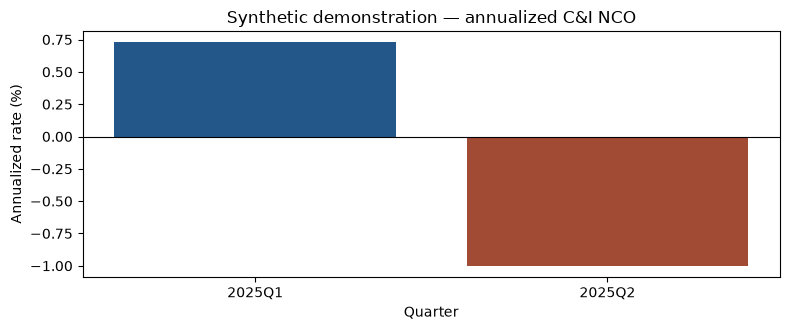

In [7]:
rates = panel.loc[pd.to_datetime(["2025-03-31", "2025-06-30"])]
assert rates.iloc[1].segment_nco == -3
np.testing.assert_allclose(rates.annualized_nco_rate_percent, rates.annualized_nco_rate * 100)
fig, ax = plt.subplots()
ax.bar(["2025Q1", "2025Q2"], rates.annualized_nco_rate_percent, color=["#235789", "#a14b35"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Synthetic demonstration — annualized C&I NCO", ylabel="Annualized rate (%)", xlabel="Quarter")
fig.tight_layout()
plt.show()

## What this establishes

The recorded excerpt supports a narrow, traceable arithmetic reconciliation.
The independent synthetic examples establish how existing code treats year
resets, gaps, reporting scope, complete components, and negative net flows.
They do not verify unreviewed filings, repair the selected-bank sample, or rebuild
the full historical panel. A ratio becomes usable only when both its numerator
and denominator satisfy their definitions; a large row count alone says little
about that eligibility.

Continue to [What the Benchmarks Say About Predictive Value](02_benchmarks_and_forecast_evidence.ipynb)
to see how eligible forecasts differ from scored outcomes. For the limits of a
fresh checkout, read [Reproducing the evidence](../docs/reproduction.md).